# GMM Customer Segmentation (simple version)

**Goal:** split customers into groups of similar buyers using a **Gaussian Mixture Model (GMM)**.

**Steps:**
1. Load the data
2. Choose the number of clusters (k) with BIC
3. Train the final model
4. Check the scores
5. Plot the clusters
6. Check how sure the model is (probabilities)
7. Describe each cluster
8. Save the results

## What is GMM? (in simple words)

- GMM assumes the customers come from **k hidden groups**, and each group looks like a **"cloud" of points** (a Gaussian / bell-shaped cloud).
- Each cloud has its own **center** and its own **shape and size**. It can be round, stretched, or tilted.
- GMM learns the clouds with the **EM algorithm**, which repeats two steps until nothing changes:
  - **E-step:** for each customer, compute the chance that they belong to each cloud.
  - **M-step:** move and reshape every cloud to fit the customers assigned to it.
- **Main difference from K-Means:** K-Means gives each customer *one* group (hard assignment). GMM gives a **probability for each group** (soft assignment), for example *"80% cluster 1, 20% cluster 3"*.

## 1. Load the data

- `Z` = the 5 PCA components. **This is what the model learns from.**
- `info` = the original, readable features (spend, invoices, ...). We use it only at the end to **describe** the clusters.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score

BASE = "../data/processed/"
Z = pd.read_csv(BASE + "customer_pca.csv", index_col="CustomerID")
info = pd.read_csv(BASE + "customer_features.csv", index_col="CustomerID").loc[Z.index]

print(Z.shape)
Z.head()

(4143, 5)


,PC1,PC2,PC3,PC4,PC5
CustomerID,,,,,
12346,-2.734894,-2.991986,2.132441,0.998034,0.468937
12347,3.589612,2.281717,-1.242719,-0.382392,-0.807583
12348,1.228287,0.845236,-0.985068,-0.459783,0.898431
12349,0.553772,5.872273,1.939445,0.008892,-0.733261
12350,-2.660162,0.845008,0.680010,0.214199,0.409236


## 2. Choose k with BIC

- We train GMM with k = 1 to 10 and compute the **BIC** for each one.
- **BIC = how well the model fits − a penalty for being too complex.** Lower is better.
- We look for the **elbow**: the point where adding one more cluster stops helping much.

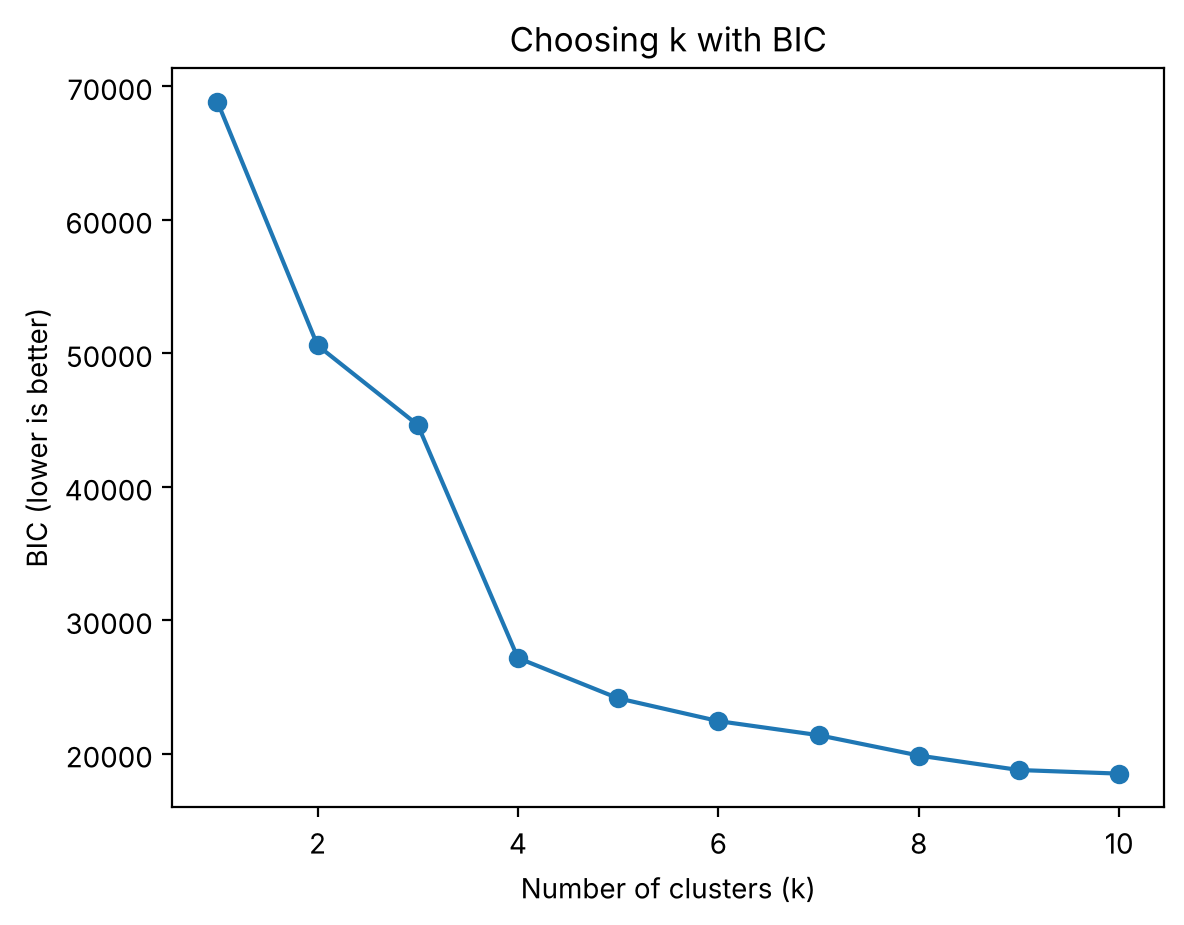

1->2     18261.0
2->3      5958.0
3->4     17461.0
4->5      3019.0
5->6      1708.0
6->7      1054.0
7->8      1526.0
8->9      1086.0
9->10      270.0
dtype: float64

In [2]:
ks = range(1, 11)
bic = []
for k in ks:
    model = GaussianMixture(n_components=k, covariance_type="full", n_init=5, random_state=42)
    model.fit(Z)
    bic.append(model.bic(Z))

plt.plot(ks, bic, marker="o")
plt.xlabel("Number of clusters (k)")
plt.ylabel("BIC (lower is better)")
plt.title("Choosing k with BIC")
plt.show()

# How much BIC drops each time we add one cluster
pd.Series(-np.diff(bic), index=[f"{k}->{k+1}" for k in range(1, 10)]).round(0)

**Result:** going from 3 → 4 clusters lowers BIC by about **17,000**, but 4 → 5 only by about **3,000**. The big gain stops at 4, so we choose **k = 4**.

## 3. Train the final model (k = 4)

- `covariance_type="full"`: every cluster can have its own shape (round, stretched, tilted). This is the most flexible option.
- `n_init=10`: train 10 times from different random starts and keep the best result.
- `random_state=42`: gives the same result every time we run it.

After training, we **renumber the clusters from lowest spender (0) to highest spender (3)** so the numbers always mean the same thing.

In [3]:
gmm = GaussianMixture(n_components=4, covariance_type="full", n_init=10, random_state=42)
gmm.fit(Z)

labels = gmm.predict(Z)        # the most likely cluster for each customer
proba = gmm.predict_proba(Z)   # the probability of each cluster for each customer

# Renumber clusters: 0 = lowest median spend ... 3 = highest median spend
order = info.groupby(labels)["Total_Spend"].median().sort_values().index
new_number = {old: new for new, old in enumerate(order)}
labels = np.array([new_number[c] for c in labels])
proba = proba[:, order]

pd.Series(labels).value_counts().sort_index().rename("customers")

0    1288
1    1311
2     360
3    1184
Name: customers, dtype: int64

## 4. Scores

- **Silhouette** (from −1 to 1, higher is better): are customers closer to their own cluster than to other clusters?
- **Davies-Bouldin** (0 or more, lower is better): how much do the clusters overlap?

In [4]:
print("Silhouette:     ", round(silhouette_score(Z, labels), 3))
print("Davies-Bouldin: ", round(davies_bouldin_score(Z, labels), 3))

Silhouette:      0.313
Davies-Bouldin:  2.45


**Result:** silhouette ≈ **0.31** and Davies-Bouldin ≈ **2.45**. The clusters exist but **overlap**. This is normal for customer data, because customers change gradually and do not fall into perfectly separate boxes.

## 5. Plot the clusters

We plot only PC1 and PC2 so we can see it in 2D. The model used all 5 components, so some clusters look more mixed here than they really are.

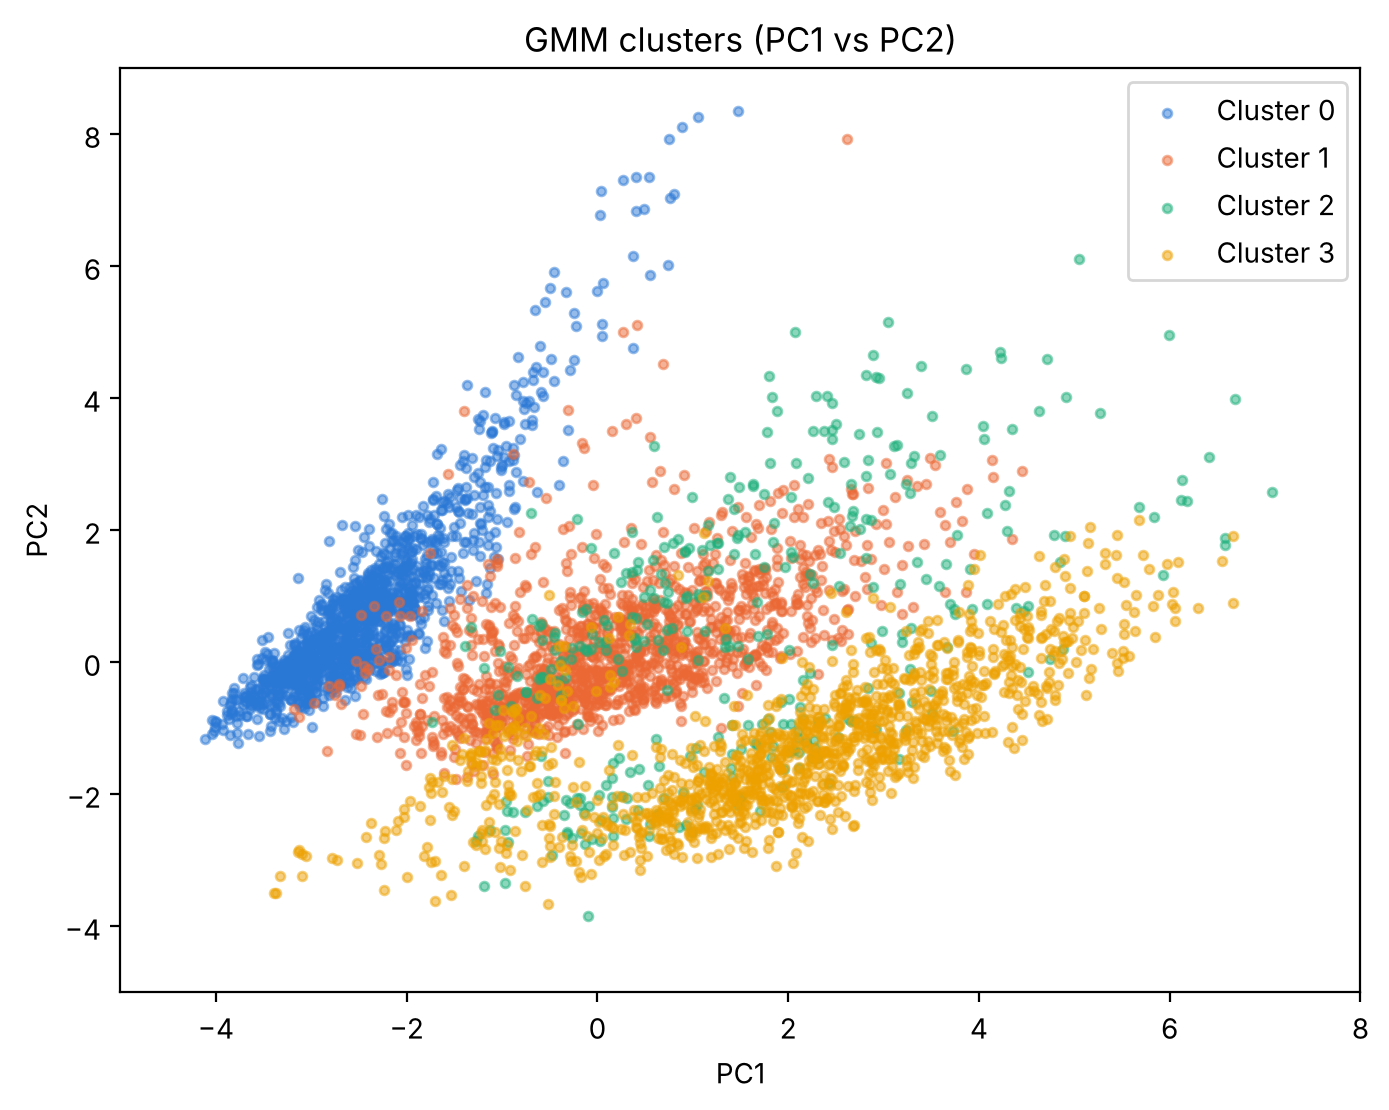

In [5]:
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # one color per cluster (0, 1, 2, 3)

plt.figure(figsize=(8, 6))
for c in range(4):
    group = Z[labels == c]
    plt.scatter(group.PC1, group.PC2, s=10, alpha=0.5, color=COLORS[c], label=f"Cluster {c}")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("GMM clusters (PC1 vs PC2)")
plt.xlim(-5, 8)    # zoom on the main cloud (4 far-away customers are outside)
plt.ylim(-5, 9)
plt.legend()
plt.show()

## 6. How sure is the model? (the special thing about GMM)

For each customer we take the **highest probability**. This is how sure the model is about that customer's cluster.

Customers with 99% certainty or more: 84.2 %
Customers below 70% certainty:       64


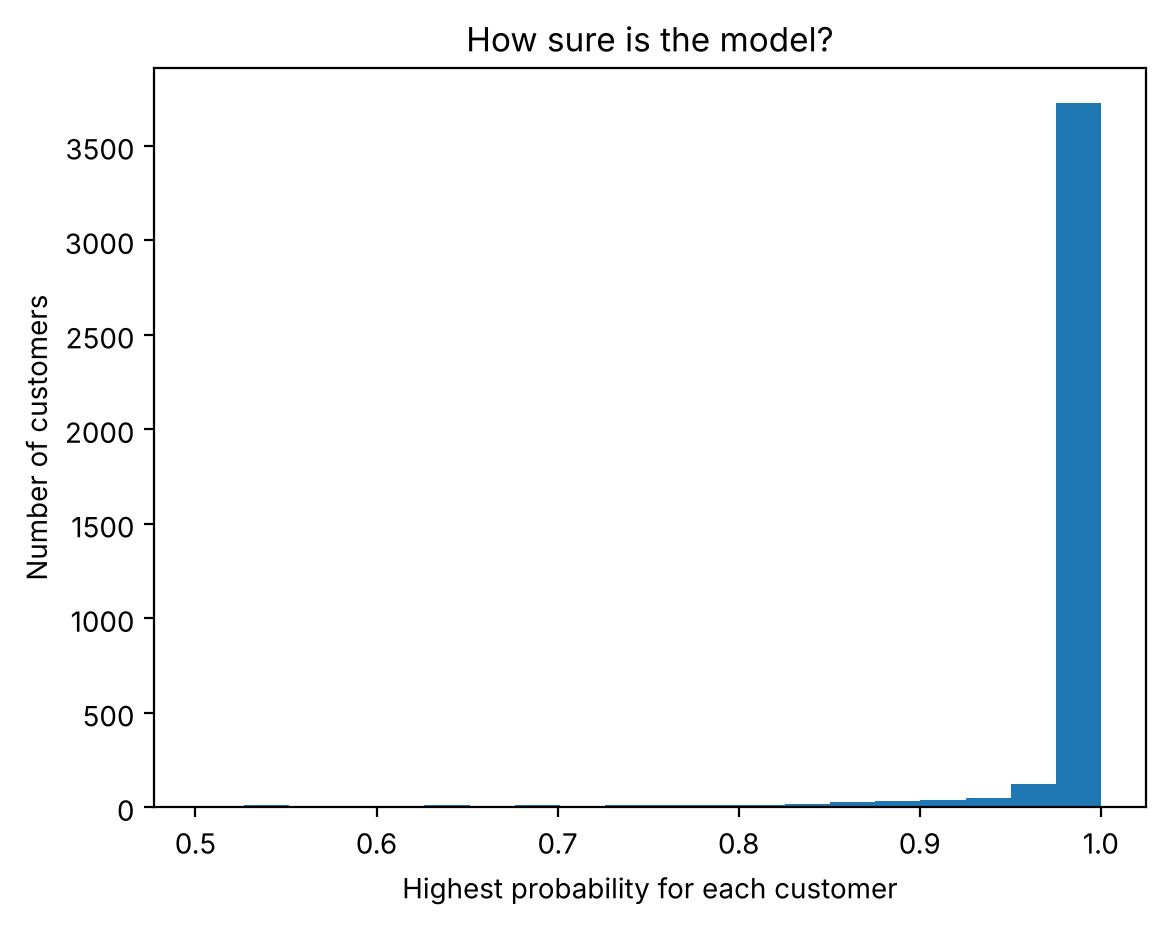

In [6]:
certainty = proba.max(axis=1)

print("Customers with 99% certainty or more:", round((certainty >= 0.99).mean() * 100, 1), "%")
print("Customers below 70% certainty:      ", (certainty < 0.70).sum())

plt.hist(certainty, bins=20)
plt.xlabel("Highest probability for each customer")
plt.ylabel("Number of customers")
plt.title("How sure is the model?")
plt.show()

**Result:** about **84%** of customers have 99%+ certainty. Only about **64 customers (1.5%)** are below 70%. These are **borderline customers** between two groups. K-Means cannot show this, but GMM can.

### Where was the model not sure?

- Every customer is drawn in the **color of their cluster** (light).
- The customers with **less than 70% certainty** are drawn as **black X**.

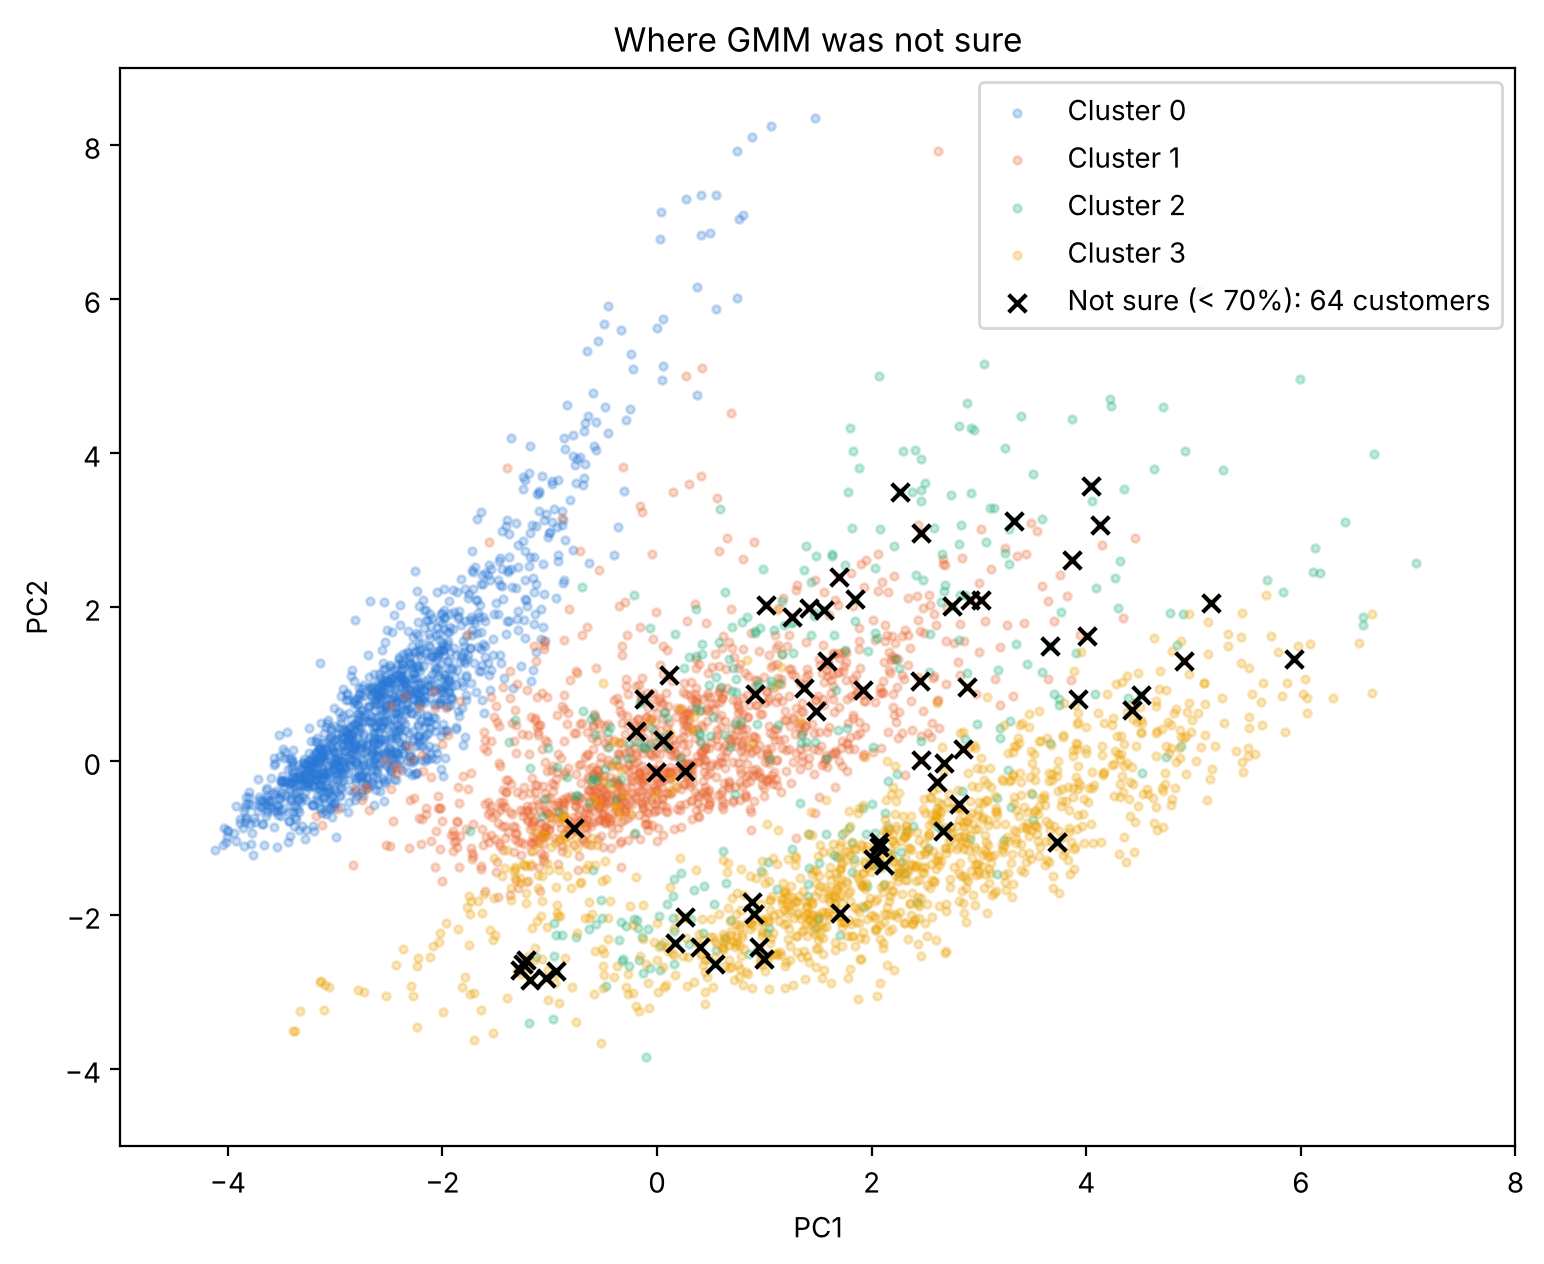

In [7]:
unsure = certainty < 0.70

plt.figure(figsize=(9, 7))
for c in range(4):
    group = Z[labels == c]
    plt.scatter(group.PC1, group.PC2, s=8, alpha=0.25, color=COLORS[c], label=f"Cluster {c}")
plt.scatter(Z.PC1[unsure], Z.PC2[unsure], s=40, marker="x", color="black",
            label=f"Not sure (< 70%): {unsure.sum()} customers")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Where GMM was not sure")
plt.xlim(-5, 8)    # zoom on the main cloud
plt.ylim(-5, 9)
plt.legend()
plt.show()

**Between which two clusters was it unsure?** For each unsure customer we take the best cluster and the second-best cluster.

In [8]:
second_best = np.argsort(proba, axis=1)[:, -2]    # the 2nd most likely cluster

pairs = [f"Cluster {min(a, b)} & {max(a, b)}" for a, b in zip(labels[unsure], second_best[unsure])]
pd.Series(pairs).value_counts().rename("unsure customers")

Cluster 2 & 3    36
Cluster 1 & 2    28
Name: unsure customers, dtype: int64

**Result:** **all 64** unsure customers are between **cluster 2** and a neighbour (36 with cluster 3, 28 with cluster 1). The model is **never unsure about cluster 0** (one-time buyers), because that group is clearly separate. Cluster 2 (big baskets, slowing down) sits between the other groups, so its edges are where the model hesitates.

## 7. Who is in each cluster?

We use the **median** of the original features for each cluster. The median is not pulled up by a few very big customers.

In [9]:
cols = ["Recency_Days", "N_Invoices", "Total_Spend", "Avg_Invoice_Value",
        "Cancellation_Rate", "Spend_Trend"]

profiles = info.assign(cluster=labels).groupby("cluster")[cols].median()

profiles["% of customers"] = pd.Series(labels).value_counts(normalize=True).sort_index().values * 100
profiles["% of total spend"] = info.groupby(labels)["Total_Spend"].sum() / info["Total_Spend"].sum() * 100

names = {
    0: "One-time buyers",
    1: "Steady repeat buyers",
    2: "Big baskets, slowing down",
    3: "Frequent buyers who return items",
}
profiles.insert(0, "segment", profiles.index.map(names))
profiles.round(2)

,segment,Recency_Days,N_Invoices,Total_Spend,Avg_Invoice_Value,Cancellation_Rate,Spend_Trend,% of customers,% of total spend
cluster,,,,,,,,,
0,One-time buyers,127.5,1.0,234.20,234.20,0.00,0.00,31.09,8.99
1,Steady repeat buyers,38.0,3.0,709.71,229.24,0.00,0.00,31.64,29.02
2,"Big baskets, slowing down",42.0,3.0,1162.16,357.59,0.00,-161.43,8.69,14.18
3,Frequent buyers who return items,26.0,6.0,1332.88,204.23,0.25,0.00,28.58,47.81


| Cluster | Segment | Customers | Spend | In simple words |
|---|---|---|---|---|
| 0 | One-time buyers | 31% | 9% | Bought once, a long time ago |
| 1 | Steady repeat buyers | 32% | 29% | Come back regularly with normal baskets |
| 2 | Big baskets, slowing down | 9% | 14% | Large orders, but their spending is going down |
| 3 | Frequent buyers who return items | 29% | 48% | Best customers by spend, but they cancel/return more |

**Key point:** cluster 3 is under a third of the customers but brings almost **half of all spending**.

### The four clusters, one picture each

Each small picture shows **one cluster in color** and all the other customers in light grey behind it. This makes it easy to see **where each group sits** and how big it is.

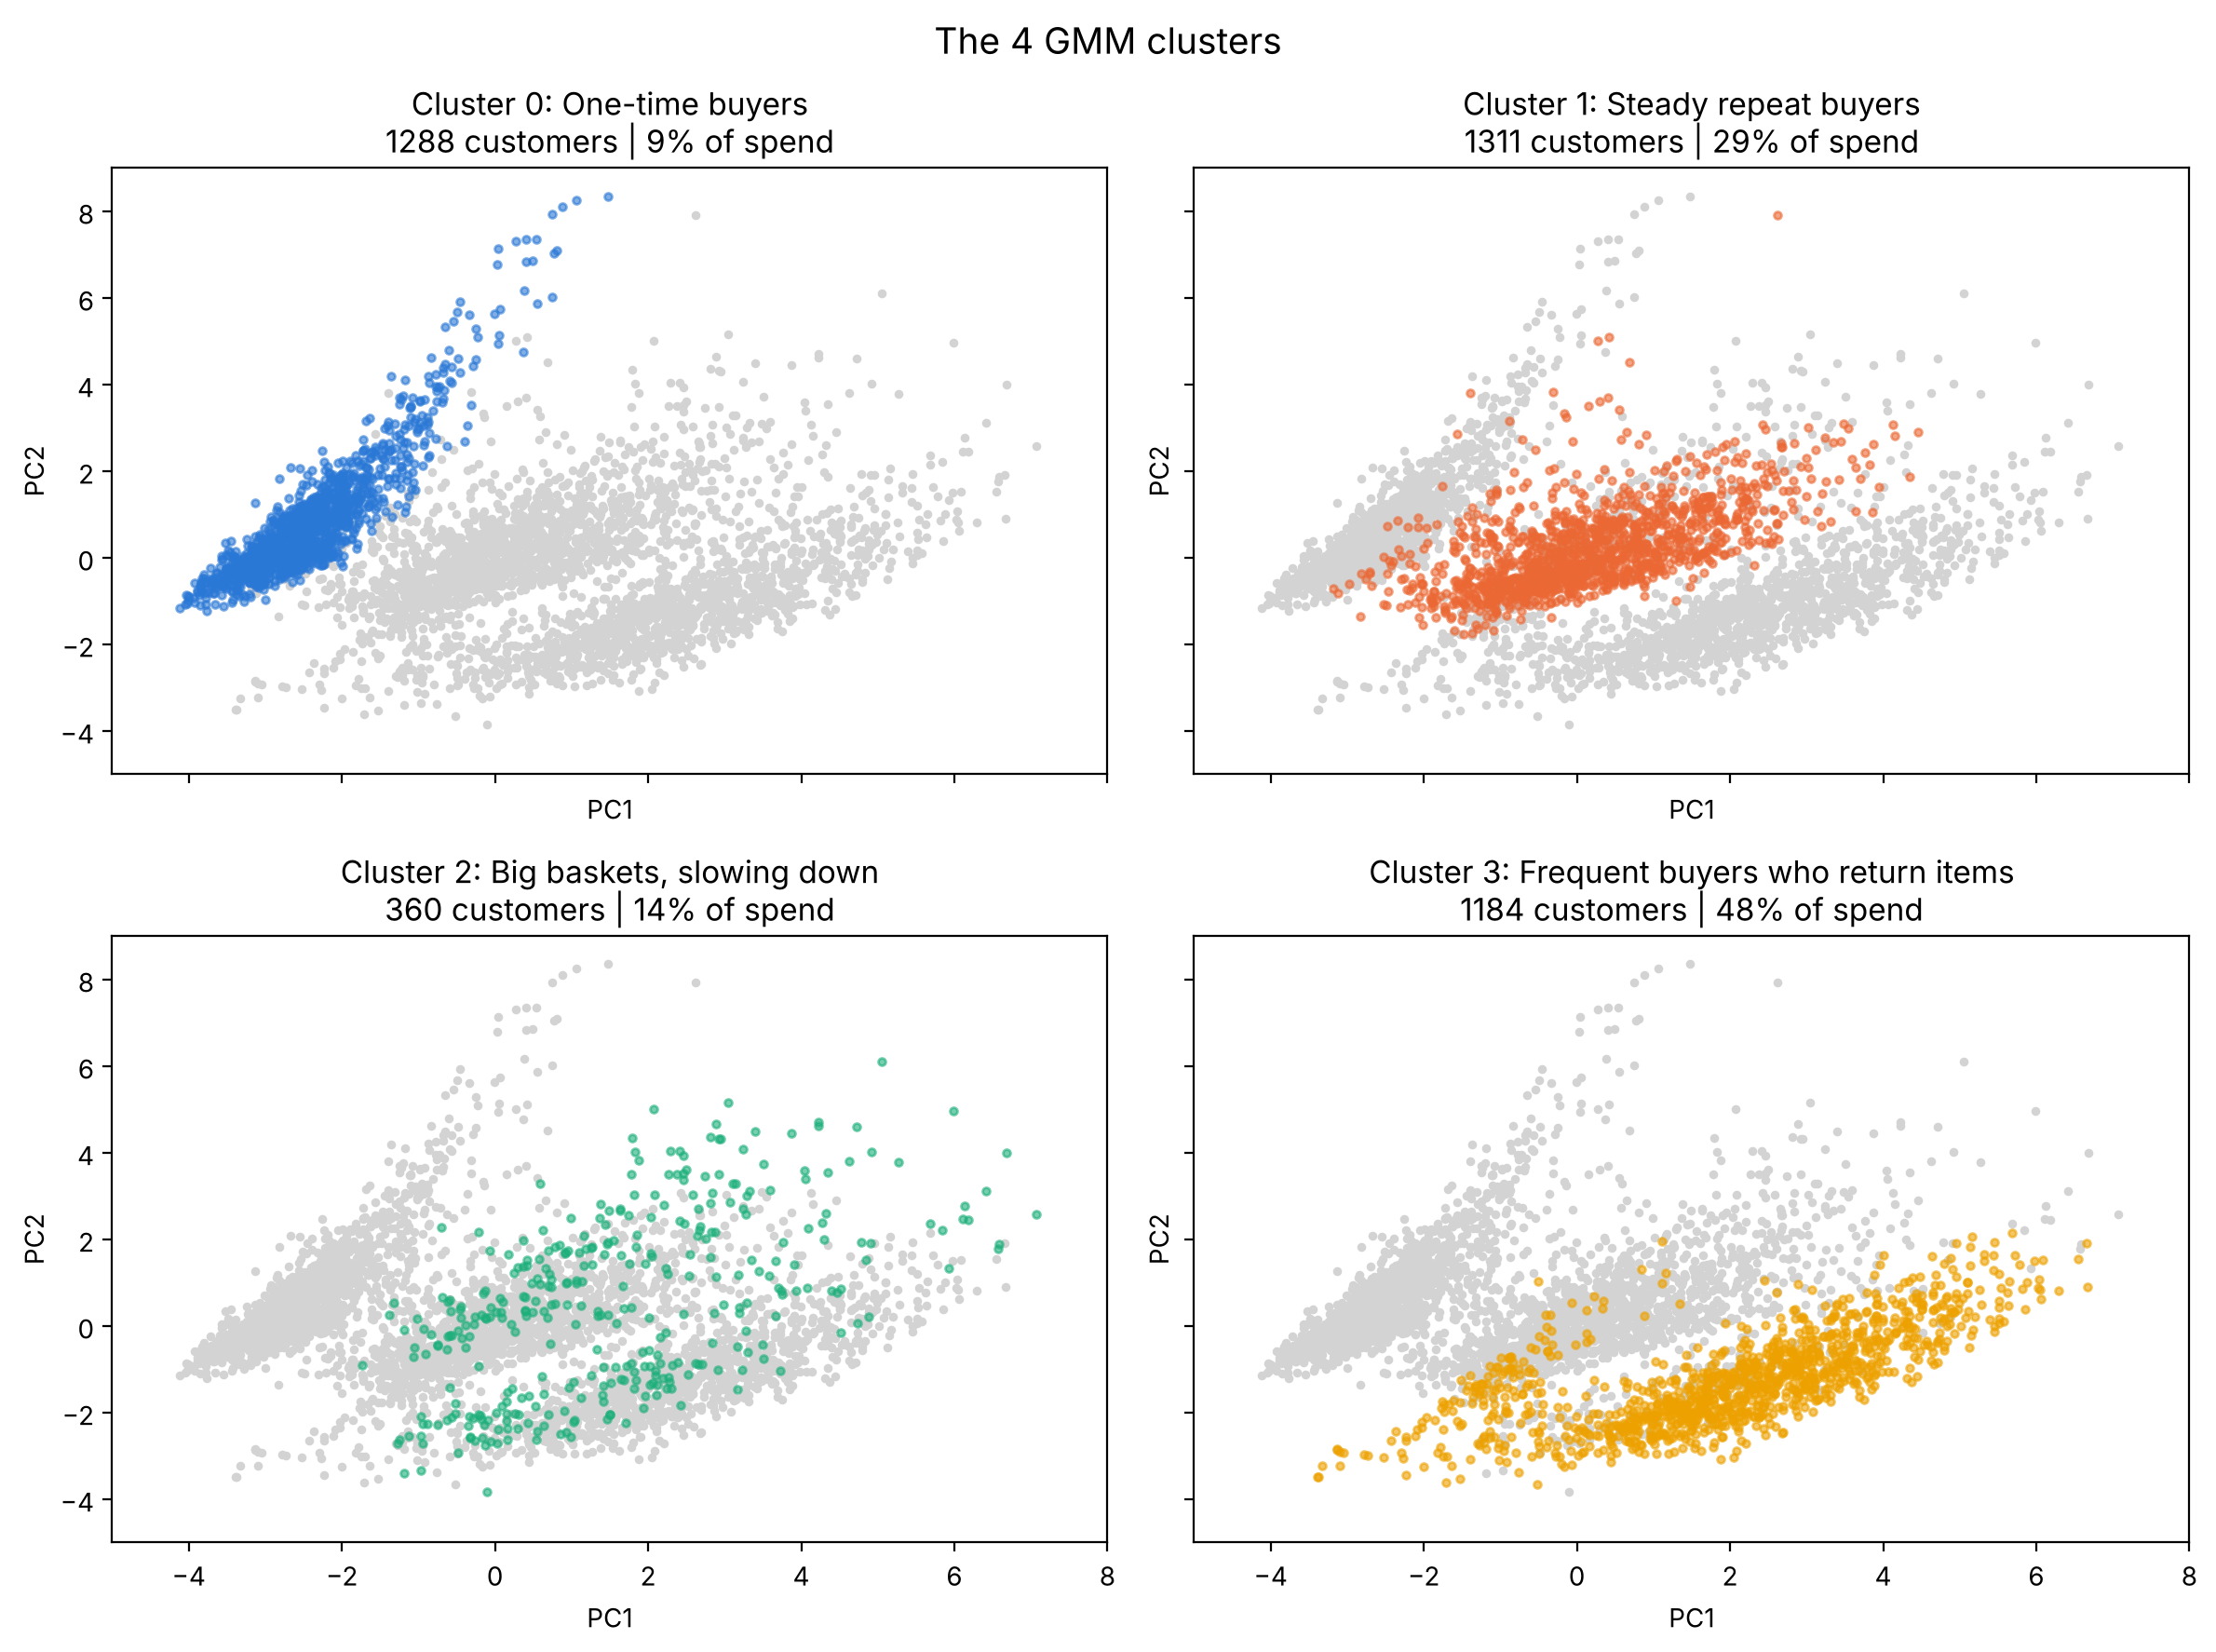

In [10]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharex=True, sharey=True)

for c, ax in enumerate(axes.flat):
    in_cluster = labels == c
    ax.scatter(Z.PC1[~in_cluster], Z.PC2[~in_cluster], s=6, color="lightgrey")          # everyone else
    ax.scatter(Z.PC1[in_cluster], Z.PC2[in_cluster], s=8, alpha=0.6, color=COLORS[c])   # this cluster
    ax.set_title(f"Cluster {c}: {names[c]}\n"
                 f"{in_cluster.sum()} customers | {profiles.loc[c, '% of total spend']:.0f}% of spend")
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    ax.set_xlim(-5, 8)    # zoom on the main cloud (4 far-away customers are outside)
    ax.set_ylim(-5, 9)

plt.suptitle("The 4 GMM clusters", fontsize=14)
plt.tight_layout()
plt.show()

## 8. Save the results

In [11]:
np.save("labels_gmm.npy", labels)   # one cluster number per customer
np.save("proba_gmm.npy", proba)     # 4 probabilities per customer

## Summary

**Strengths of GMM**
- Gives a **probability** for each cluster, not just one label, so we can find borderline customers.
- Clusters can have **different shapes and sizes** (not only round like K-Means).
- **BIC** gives a clear way to choose k.

**Weaknesses of GMM**
- You still have to choose k.
- It assumes each cluster is a bell-shaped cloud, which is not always true.
- Every customer is put in a cluster. There is **no "noise" label** for outliers (DBSCAN has one).
- Results can change with the random start, so we use `n_init` and `random_state`.

**Compared with K-Means (k = 4):** K-Means has a slightly higher silhouette (0.36 vs 0.31), and the two methods mostly agree (ARI = 0.67). GMM adds the probabilities and more flexible cluster shapes.